# Experiment No: 17

## Linear Regression for a Given Data Set

**Aim:** To understand the Linear Regression algorithm for the given Salary data set.

In [1]:
%pip install -q scikit-learn
import numpy as np
import pandas as pd

data = {
    'YearsExperience': [
        1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5
    ],
    'Salary': [
        39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445,
        64445, 57189, 63218, 55794, 56957, 57081, 61111, 67938,
        66029, 83088, 81363, 93940, 91738, 98273, 101302, 113812,
        109431, 105582, 116969, 112635, 122391, 121872
    ]
}
pd.DataFrame(data).to_csv('Salary_data.csv', index=False)
print("Salary_data.csv created successfully")

Note: you may need to restart the kernel to use updated packages.


Salary_data.csv created successfully


In [2]:
df = pd.read_csv('Salary_data.csv')
df

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.2,64445
9,3.7,57189


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 608.0 bytes


In [4]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [5]:
features = df.iloc[:, [0]].values
label = df.iloc[:, [1]].values

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(features, label,
                                                    test_size=0.2,
                                                    random_state=0)

In [6]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [7]:
print("Training score:", model.score(x_train, y_train))
print("Testing score:", model.score(x_test, y_test))

Training score: 0.9411949620562126
Testing score: 0.988169515729126


In [8]:
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Coefficient: [[9312.57512673]]
Intercept: [26780.09915063]


In [9]:
yr_of_exp = 5.5
yr_of_exp_NP = np.array([[yr_of_exp]])
salary = model.predict(yr_of_exp_NP)
print("Estimated Salary for {} years of experience is {}".format(yr_of_exp, salary))

Estimated Salary for 5.5 years of experience is [[77999.26234764]]


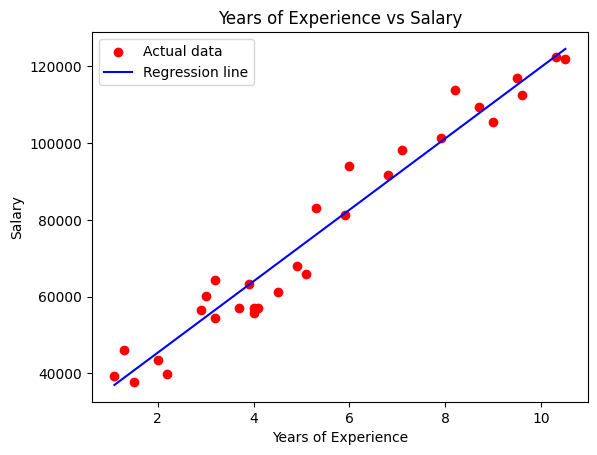

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.scatter(features, label, color='red', label='Actual data')
plt.plot(features, model.predict(features), color='blue', label='Regression line')
plt.title('Years of Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.show()